# Validate against buoy observations

Compare **offshore hindcast** (closest goal node), **bulk metamodel**, **spectral metamodel**, and **dynamic SnapWave** to buoy records.

**Prerequisites**

1. Fitted models — `06_Validate_Metamodel.ipynb` (`mm.fit_all`)
2. Dynamic run for the same period — `08_Dynamic_Cases_Generation.ipynb`
3. Observations GeoJSON — `03_Generate_Observations_Configuration.ipynb` → `inputs/Observations/<Case>_observations.json`
4. Processed hourly buoy files in `inputs/Observations/processed/` (notebook 03,
   `utils/buoy_archive.py`).

Use the **same `period`** for buoy data, reconstruction, and dynamic output.

Comparisons request **`hs`, `tp`, `dir`, and `spr`**. Variables missing from the buoy
file or any model are skipped automatically.

The buoys validated are
the `ok` buoy sites of `outputs/output_sites_{model}.csv` (notebook 03) that have
`hs` in `period`; buoys outside the mesh or that can dry have no model output.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import xarray as xr
from utils import metamodel as mm
from utils import onshore_sites as obs
from utils import simulation as sim
from utils import validation as val
from utils.config import resolve
from utils.geometry import attach_site_meta

## Configuration

The modelled buoys of the observations GeoJSON (`instrument_id` keys that are `ok`
output sites, notebook 03). Site labels are `buoy_{instrument_id}`. Processed hourly files (`hs`, `tp`, `dir`,
`spr` where measured) come from `utils/buoy_archive.py` (Waterinfo + CMEMS + the
earlier Rijkswaterstaat exports), built in notebook 03.

In [2]:
period = slice("2013-01-01", "2013-12-31")  # matches the 09/reconstruction cache span
offshore_name = "WHACS_cal"
mda_n = 550  # must match a fitted mda_candidates entry
mm_set = "buoys"  # metamodel set (metamodel.sets) fitted on the buoys

# Modelled buoys (ok output sites, notebook 03); processed hourly files
# (hs, tp, dir, spr) in inputs/Observations/processed/<instrument_id>.nc
sites = obs.list_snapwave_buoy_sites()
buoy_instruments = [obs.instrument_id(s) for s in sites]

requested_variables = ["hs", "tp", "dir", "spr"]

dynamic_path = sim.cases_dir("dynamic") / f"Dynamic_Cases_{offshore_name}_2013.nc"

print("Observations JSON:", obs.geojson_path())
print(f"period         : {period}")
print(f"mda_n          : {mda_n}")
print(f"metamodel      : {mm_set}")
print(f"sites          : {sites}")
print(f"requested vars : {requested_variables}")
print(f"dynamic path   : {dynamic_path}")
print(f"dynamic exists : {dynamic_path.is_file()}")

Observations JSON: /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/Observations/Netherlands_observations.json
period         : slice('2013-01-01', '2013-12-31', None)
mda_n          : 550
metamodel      : buoys
sites          : ['buoy_A2', 'buoy_AWG', 'buoy_Akkaert', 'buoy_Amelander31', 'buoy_AmelanderZeegat_1_1', 'buoy_BolVanHeistBuoy', 'buoy_Brouwershavensegat', 'buoy_CadzandBoei', 'buoy_Deurlo', 'buoy_DomburgerRassen', 'buoy_EierlandseGat', 'buoy_EurogeulDWE', 'buoy_EurogeulE13', 'buoy_EurogeulE5', 'buoy_Europlatform', 'buoy_GoereeLichteiland', 'buoy_IJgeul', 'buoy_IJgeulStroommeetpaal', 'buoy_IJmuidenMunitiestort_1', 'buoy_KwintebankBuoy', 'buoy_L91', 'buoy_MeetboeiWEO1', 'buoy_OostendNorth', 'buoy_Oosterschelde11', 'buoy_OstendEasternPalisadeBuoy', 'buoy_OstendPoortjesBuoy', 'buoy_PettenMeetraai01', 'buoy_Q1', 'buoy_Raversijde2', 'buoy_ScheurWest', 'buoy_SchiermonnikoogNoord', 'buoy_SchiermonnikoogWestgat', 'buoy_Schouwenbank', 'buoy_StortemelkWest', 'buoy_Th

## 1 · Check models

In [3]:
mm.require_models(mm_set, mda_n)

## 2 · Buoy observations

**2a.** The processed hourly file of each buoy (built in notebook 03 by
`utils/buoy_archive.py`), with its number of valid `hs` hours in `period`.

**2b.** Load each processed file, slice to `period`, and build a validation dataset
on `(time, sites)` with CF-style attributes. Site metadata (lon/lat/depth) comes
from the observations GeoJSON.

In [4]:
processed_dir = resolve("inputs/Observations/processed")

# Processed observation NetCDF per SnapWave site id (notebook 03)
buoy_raw_files: dict[str, Path] = {}
n_valid_hs: dict[str, int] = {}
for instrument_id in buoy_instruments:
    site_id = obs.snapwave_site_id(instrument_id)
    buoy_raw_files[site_id] = processed_dir / f"{instrument_id}.nc"
    with xr.open_dataset(buoy_raw_files[site_id]) as check:
        n_valid_hs[site_id] = int(check["hs"].sel(time=period).notnull().sum())
    print(f"{site_id}: {n_valid_hs[site_id]} valid hourly hs in {period}")

no_data = [s for s in sites if n_valid_hs[s] == 0]
sites = [s for s in sites if n_valid_hs[s] > 0]
print(f"\n{len(sites)} buoys with hs in {period}; skipped (no data): {no_data}")

buoy_A2: 0 valid hourly hs in slice('2013-01-01', '2013-12-31', None)
buoy_AWG: 7255 valid hourly hs in slice('2013-01-01', '2013-12-31', None)
buoy_Akkaert: 0 valid hourly hs in slice('2013-01-01', '2013-12-31', None)
buoy_Amelander31: 6239 valid hourly hs in slice('2013-01-01', '2013-12-31', None)
buoy_AmelanderZeegat_1_1: 6317 valid hourly hs in slice('2013-01-01', '2013-12-31', None)
buoy_BolVanHeistBuoy: 0 valid hourly hs in slice('2013-01-01', '2013-12-31', None)
buoy_Brouwershavensegat: 8744 valid hourly hs in slice('2013-01-01', '2013-12-31', None)
buoy_CadzandBoei: 8740 valid hourly hs in slice('2013-01-01', '2013-12-31', None)
buoy_Deurlo: 6948 valid hourly hs in slice('2013-01-01', '2013-12-31', None)
buoy_DomburgerRassen: 0 valid hourly hs in slice('2013-01-01', '2013-12-31', None)
buoy_EierlandseGat: 6552 valid hourly hs in slice('2013-01-01', '2013-12-31', None)
buoy_EurogeulDWE: 7004 valid hourly hs in slice('2013-01-01', '2013-12-31', None)
buoy_EurogeulE13: 7785 valid 

In [5]:
# CF-style attributes for validation plots
_BUOY_VAR_ATTRS = {
    "hs": {"standard_name": "sea_surface_wave_significant_height", "units": "m"},
    "tp": {"standard_name": "sea_surface_wave_period", "units": "s"},
    "dir": {"standard_name": "sea_surface_wave_from_direction", "units": "degree"},
    "spr": {
        "standard_name": "sea_surface_wave_directional_spread",
        "units": "degree",
    },
}

chunks: list[xr.Dataset] = []
for site_id in sites:
    raw = xr.open_dataset(resolve(buoy_raw_files[site_id])).sel(time=period)

    if "Efth" in raw or "efth" in raw:
        spec_name = "Efth" if "Efth" in raw else "efth"
        stats = raw[spec_name].spec.stats(["hs", "tp", "dm", "dspr"]).load()
        site_ds = stats.rename({"dm": "dir", "dspr": "spr"})
    else:
        rename = {}
        if "dspr" in raw.data_vars and "spr" not in raw.data_vars:
            rename["dspr"] = "spr"
        if rename:
            raw = raw.rename(rename)
        vars_out = {}
        for name in requested_variables:
            if name in raw.data_vars:
                vars_out[name] = raw[name]
            elif name == "dir" and "dm" in raw.data_vars:
                vars_out["dir"] = raw["dm"]
        if "hs" not in vars_out:
            raise ValueError(f"{site_id}: processed buoy file must contain hs or Efth")
        site_ds = xr.Dataset(vars_out)

    site_ds = site_ds.expand_dims(sites=[site_id]).transpose("time", "sites")
    for var, attrs in _BUOY_VAR_ATTRS.items():
        if var in site_ds:
            site_ds[var].attrs.update(attrs)
    chunks.append(site_ds)

buoy = attach_site_meta(xr.concat(chunks, dim="sites"))
buoy

<xarray.Dataset> Size: 8MB
Dimensions:             (time: 8760, sites: 27)
Coordinates:
  * time                (time) datetime64[ns] 70kB 2013-01-01 ... 2013-12-31T...
  * sites               (sites) object 216B 'buoy_AWG' ... 'buoy_zdv8-2d-MMND'
    site_source         (sites) <U4 432B 'buoy' 'buoy' 'buoy' ... 'buoy' 'buoy'
    site_label          (sites) <U22 2kB 'AWG' 'Amelander31' ... 'zdv8-2d-MMND'
    site_longitude      (sites) float64 216B 5.95 5.6 5.481 ... 6.367 3.42 4.01
    site_latitude       (sites) float64 216B 53.5 53.45 53.51 ... 51.43 51.99
    site_mesh_depth     (sites) float64 216B 9.97 14.97 19.15 ... 13.55 16.03
    site_nominal_depth  (sites) float64 216B 11.0 13.0 18.0 ... 15.0 8.0 21.0
Data variables:
    hs                  (time, sites) float64 2MB nan 0.456 1.376 ... nan 0.915
    tp                  (time, sites) float64 2MB nan 4.239 8.788 ... nan nan
    dir                 (time, sites) float64 2MB nan nan 265.4 ... nan nan
    spr                 (time, sites) float64 2MB nan nan nan ... 69.5 nan nan

## 3 · Reconstruct metamodel, load dynamic, and closest-goal offshore hindcast

Metamodel bulk/spectral reconstructions, dynamic SnapWave, and bulk offshore forcing
at each buoy's **closest goal hindcast node** (all sources in the case JSON —
currently WHACS only).

In [7]:
timings: dict[str, float] = {}

t0 = time.perf_counter()
bulk = mm.reconstruct(
    period,
    mda_n,
    metamodel=mm_set,
    spectral=False,
    offshore_name=offshore_name,
    sites=sites,
    save_spectra=False,
)
bulk_wind = mm.reconstruct(
    period,
    mda_n,
    metamodel=mm_set,
    spectral=False,
    offshore_name=offshore_name,
    sites=sites,
    save_spectra=False,
    wind_correction=True,
)
timings["Bulk metamodel"] = time.perf_counter() - t0

t0 = time.perf_counter()
spectral = mm.reconstruct(
    period,
    mda_n,
    metamodel=mm_set,
    spectral=True,
    offshore_name=offshore_name,
    sites=sites,
    save_spectra=False,
)
spectral_wind = mm.reconstruct(
    period,
    mda_n,
    metamodel=mm_set,
    spectral=True,
    offshore_name=offshore_name,
    sites=sites,
    save_spectra=False,
    wind_correction=True,
)
timings["Spectral metamodel"] = time.perf_counter() - t0

if not dynamic_path.is_file():
    raise FileNotFoundError(
        f"Dynamic output not found: {dynamic_path}\n"
        "Run 08_Dynamic_Cases_Generation for this period or change `period`."
    )

dynamic = xr.open_dataset(dynamic_path).sel(time=period)
dynamic = dynamic.sel(sites=bulk.sites.values).load()

offshore_hindcast, closest_goals = val.load_offshore_hindcast_at_buoys(
    period,
    sites,
    variables=requested_variables,
)

estimates = {
    **offshore_hindcast,
    "Bulk metamodel": bulk,
    "Bulk metamodel (wind-corrected)": bulk_wind,
    "Spectral metamodel": spectral,
    "Spectral metamodel (wind-corrected)": spectral_wind,
    val.DYNAMIC_REFERENCE_LABEL: dynamic,
}

variables = val.resolve_comparison_variables(
    buoy,
    *estimates.values(),
    variables=requested_variables,
)
print(f"Comparing: {variables}")

Comparing: ['hs', 'tp', 'dir', 'spr']


## 4 · Metrics vs buoy

In [8]:
results = val.compare_all(
    buoy,
    estimates,
    variables=variables,
    reference_label="Buoy",
)

summary = val.metrics_summary(results)
summary

,pca_variances,group,site_source,site_label,variable,label,n,bias,rmse,rrmse,si,r,r2,reference_label,estimate_label,model
0,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_AWG,buoy,waves,hs,Hs,7255,0.593055,0.786563,0.944032,0.516765,0.780547,-1.025201,Buoy,WHACS (closest goal),WHACS (closest goal)
1,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_AWG,buoy,waves,tp,Tp,8052,-4.844725,5.993920,0.502396,0.277880,0.587747,-0.894202,Buoy,WHACS (closest goal),WHACS (closest goal)
2,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_AWG,buoy,waves,dir,Dir,0,NaN,NaN,NaN,NaN,NaN,NaN,Buoy,WHACS (closest goal),WHACS (closest goal)
3,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_AWG,buoy,waves,spr,Spr,0,NaN,NaN,NaN,NaN,NaN,NaN,Buoy,WHACS (closest goal),WHACS (closest goal)
4,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_Amelander31,buoy,waves,hs,Hs,6239,1.161360,1.369032,2.673798,1.240550,0.678556,-22.636358,Buoy,WHACS (closest goal),WHACS (closest goal)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
859,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_WielingenNoord,buoy,waves,spr,Spr,0,NaN,NaN,NaN,NaN,NaN,NaN,Buoy,Dynamic SnapWave,Dynamic SnapWave
860,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_zdv8-2d-MMND,buoy,waves,hs,Hs,5165,0.066106,0.391994,0.406584,0.337953,0.819800,0.593068,Buoy,Dynamic SnapWave,Dynamic SnapWave
861,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_zdv8-2d-MMND,buoy,waves,tp,Tp,3553,0.696054,1.593338,0.283838,0.245636,0.566724,-0.001834,Buoy,Dynamic SnapWave,Dynamic SnapWave
862,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_zdv8-2d-MMND,buoy,waves,dir,Dir,0,NaN,NaN,NaN,NaN,NaN,NaN,Buoy,Dynamic SnapWave,Dynamic SnapWave


## 4b · Save summary

In [9]:
# `period` is a slice here (not a single string) — derive a clean,
# filesystem-safe label from it once; the summary PNG save cell reuses it.
period_label = period if isinstance(period, str) else f"{period.start}-{period.stop}"

summary_out = summary.copy()
summary_out.insert(0, "period", period_label)
summary_out.insert(1, "metamodel", mm_set)
summary_out.insert(2, "mda_candidate", mda_n)
summary_out.insert(3, "offshore_name", offshore_name)
summary_out["reconstruct_seconds"] = summary_out["model"].map(timings)

out_path = val.buoy_validation_path("onshore", period_label)
out_path.parent.mkdir(parents=True, exist_ok=True)
summary_out.to_csv(out_path, index=False)
print(f"Wrote {out_path}")

Wrote /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/onshore_summary_2013-01-01-2013-12-31.csv


## 5 · Scatter plots

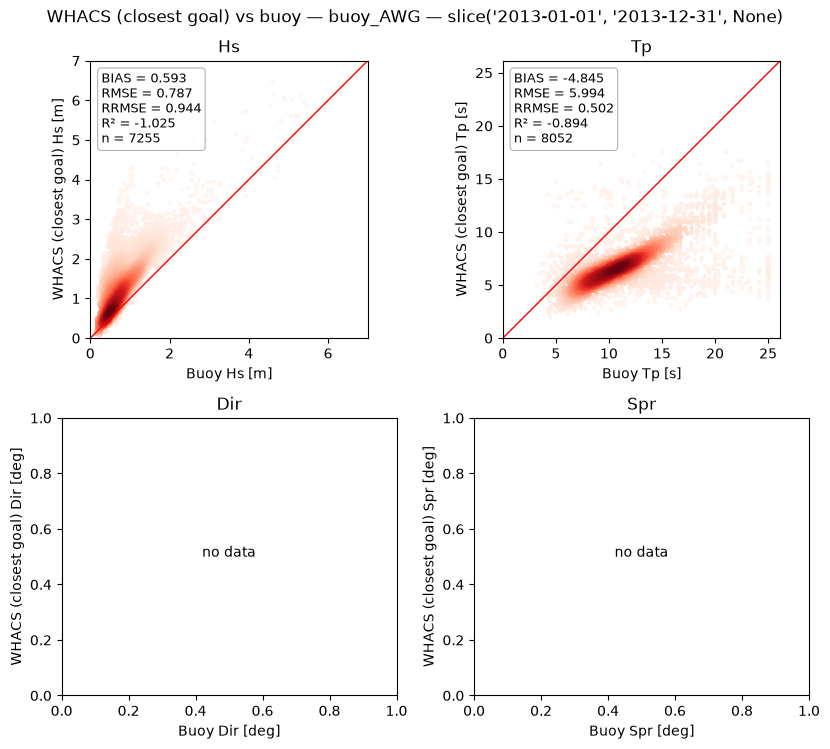

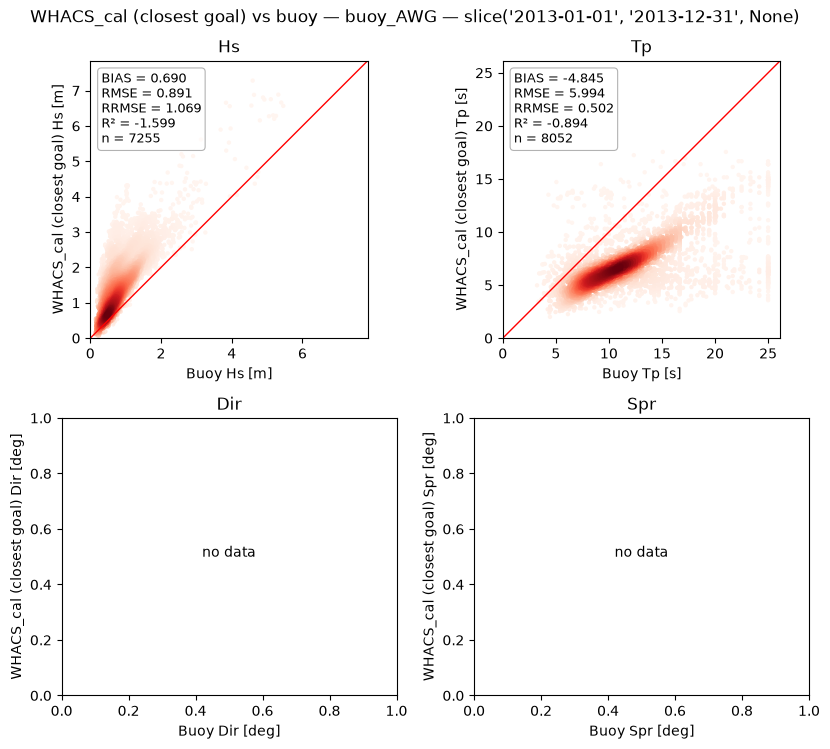

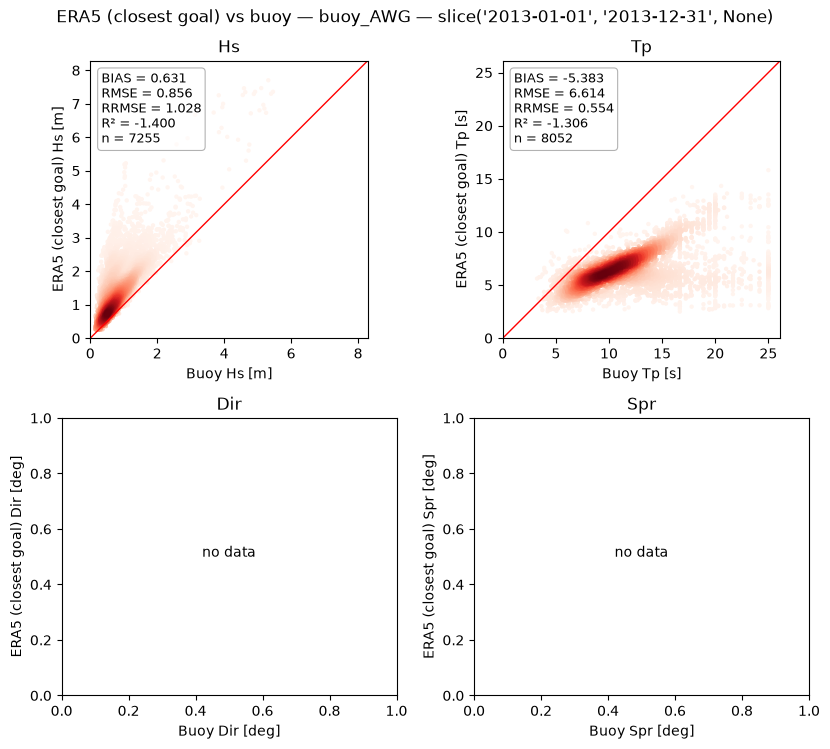

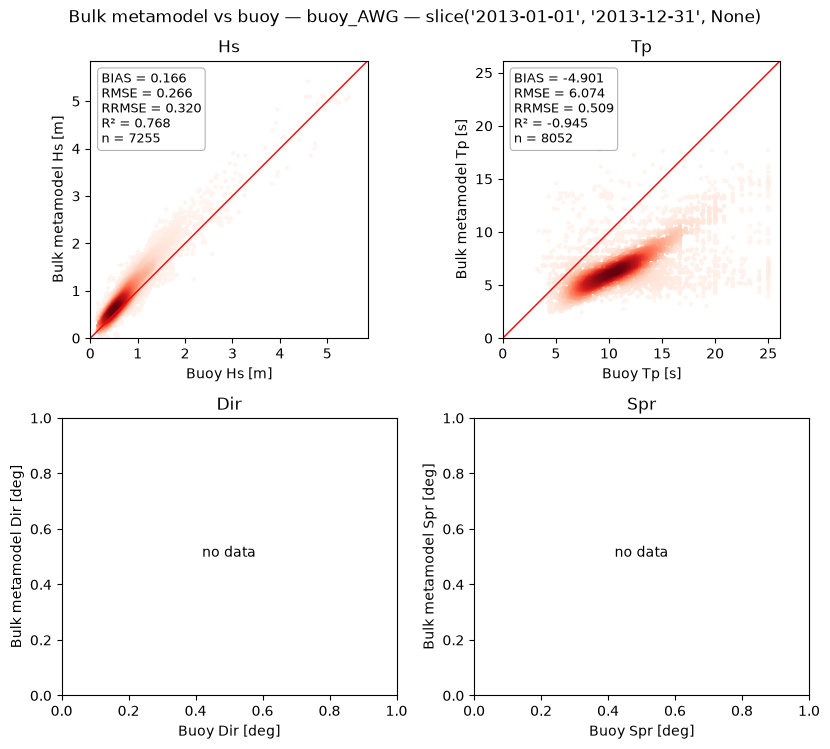

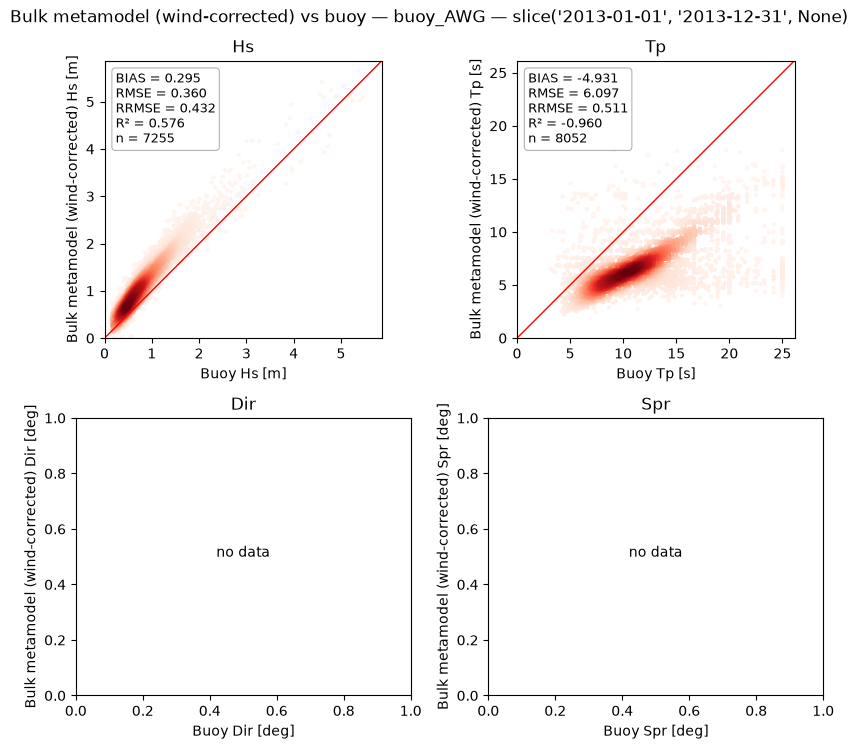

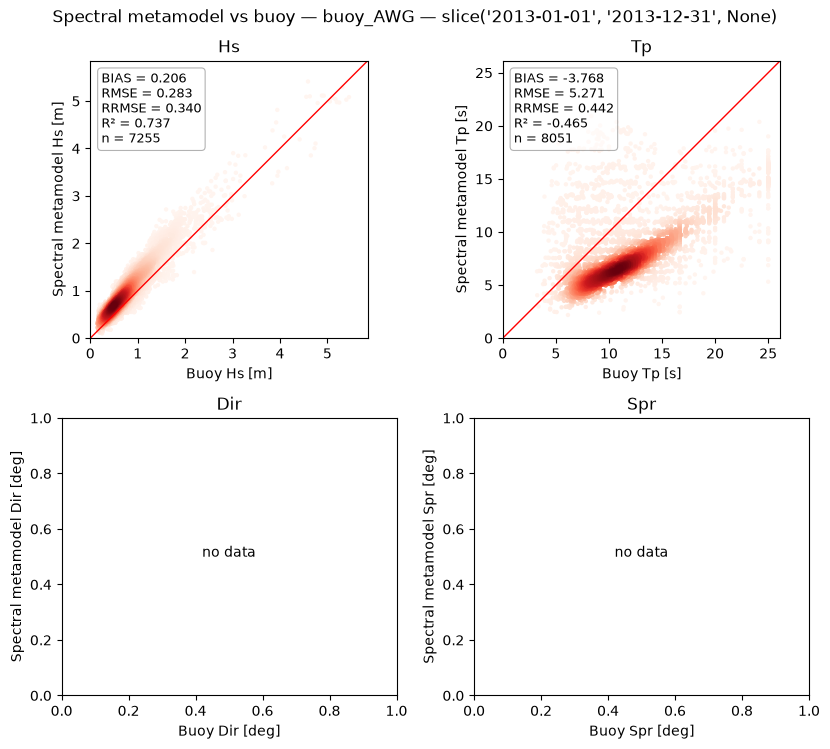

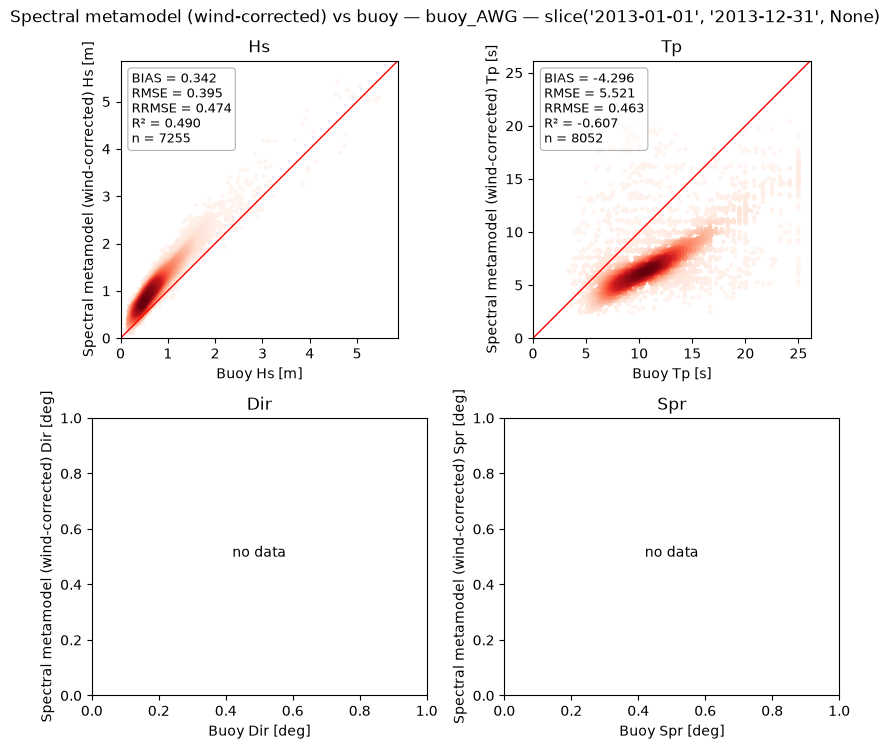

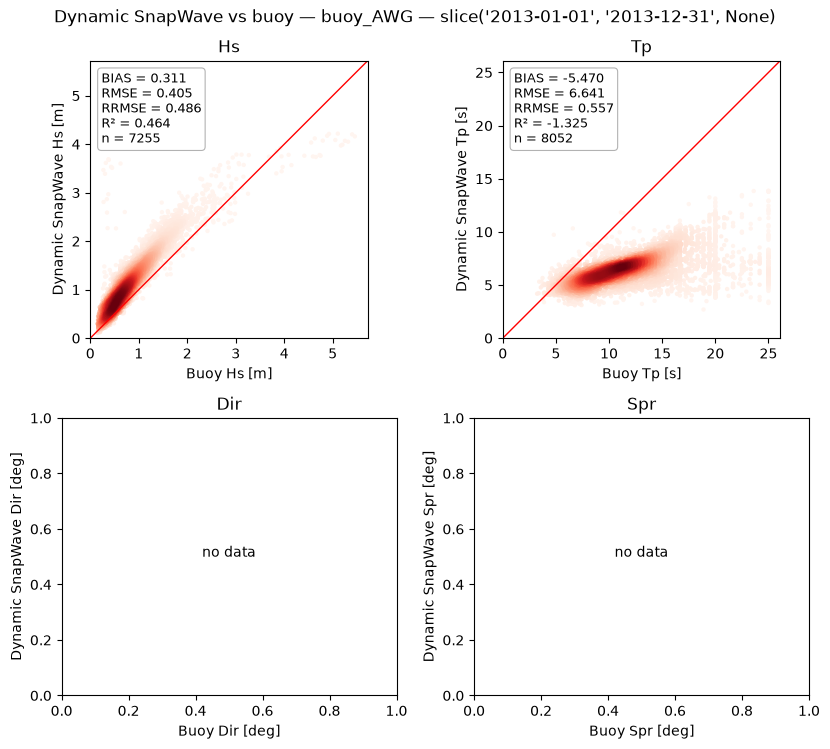

In [11]:
for site in sites:
    for name, result in results.items():
        result.plot_scatter(site, variables)
        plt.suptitle(f"{name} vs buoy — {site} — {period}")
        plt.show()
    break

## 6 · Time series

Line plots of buoy observations vs each model over the validation period (direction as scatter).

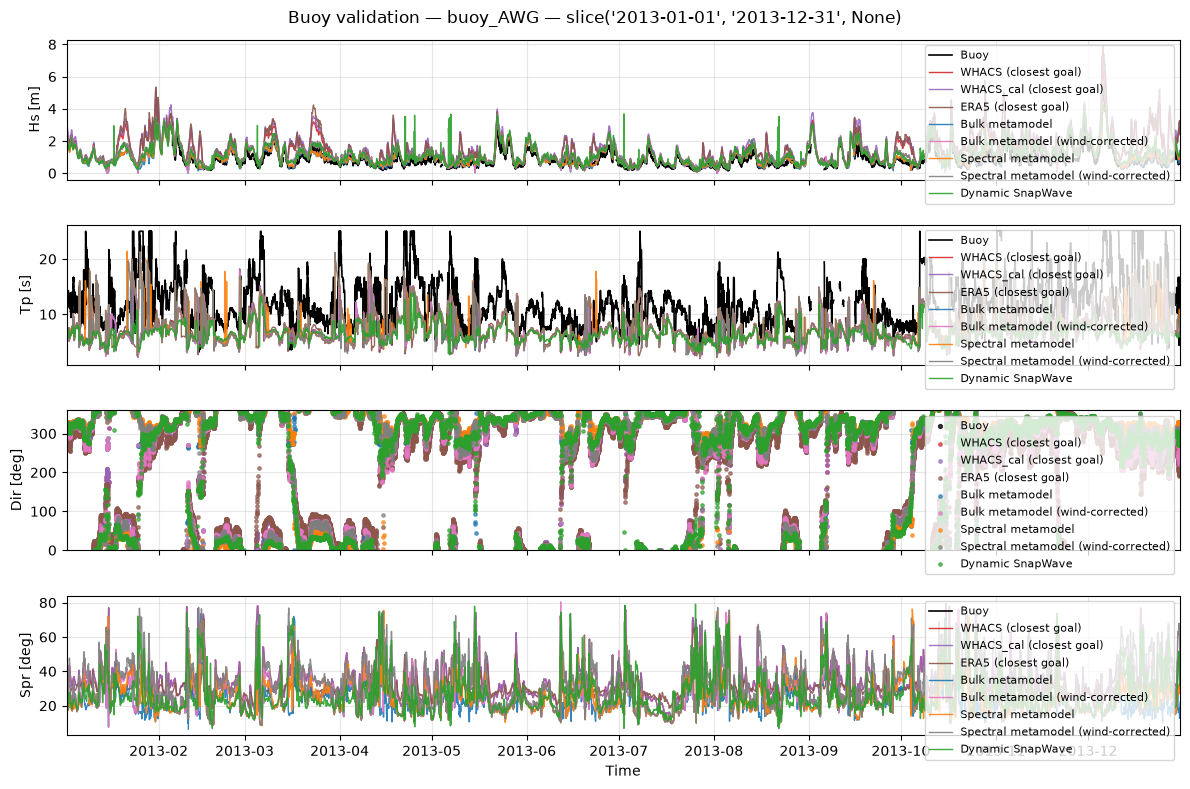

In [12]:
for site in sites:
    val.plot_buoy_timeseries(buoy, estimates, site, variables=variables)
    plt.suptitle(f"Buoy validation — {site} — {period}")
    plt.show()
    break

## 7 · Save per-buoy summary PNG (GUI)

Density scatter (top row, buoy vs. spectral metamodel) + one wide Hs/Tp time series (bottom row, cropped to when the buoy actually has data) — one combined PNG per buoy, shown as-is in the GUI's Buoy Validation tab when you click that buoy's star on the map.

In [13]:
for site in sites:
    fig = val.plot_buoy_summary(
        buoy,
        estimates["Spectral metamodel"],
        site,
        variables=variables,
        reference_label="Buoy",
        period_label=period_label,
        estimate_label="Spectral metamodel",
    )
    out_path = val.buoy_summary_figure_path(site)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_path, dpi=150, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print(f"saved {out_path}")

saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_AWG.png
saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_Amelander31.png
saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_AmelanderZeegat_1_1.png
saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_Brouwershavensegat.png
saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_CadzandBoei.png
saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_Deurlo.png
saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_EierlandseGat.png
saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_EurogeulDWE.png
saved /lustre/geocea